<a href="https://colab.research.google.com/github/SkrybaOtis/Systemy_AI/blob/main/SystemyAI_Lab3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Systemy AI – Laboratorium 3
## Titanic: wybieranie danych, braki, tabele przestawne i pierwszy klasyfikator

**Cel:** przygotować prawdziwy zbiór danych do modelowania (wybieranie wierszy i kolumn, braki danych, grupowanie), zwizualizować go i zbudować pierwszy klasyfikator, który „uczy się” z danych.


---
## Przygotowanie

Komórka poniżej wczytuje biblioteki i dane oraz definiuje funkcję `binary_metrics` z Lab 1 (tym razem gotową). Uruchom ją i nic w niej nie zmieniaj.

Zbiór opisuje 891 pasażerów Titanica. Zadanie klasyfikacji binarnej: przewidzieć kolumnę `survived`.

| Kolumna | Znaczenie |
|---|---|
| `survived` | **etykieta**: 1 = przeżył/a, 0 = nie |
| `pclass` | klasa podróży: 1, 2 lub 3 |
| `sex` | płeć: `"male"` / `"female"` |
| `age` | wiek w latach (są braki!) |
| `fare` | cena biletu |
| `embarked` | port zaokrętowania: S = Southampton, C = Cherbourg, Q = Queenstown (są braki!) |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = sns.load_dataset("titanic")
df = df[["survived", "pclass", "sex", "age", "fare", "embarked"]].copy()


def binary_metrics(y_true, y_pred):
    """Metryki klasyfikacji binarnej (z Lab 1). Metryka z zerowym mianownikiem = 0.0."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    TP = int(np.sum((y_true == 1) & (y_pred == 1)))
    FP = int(np.sum((y_true == 0) & (y_pred == 1)))
    FN = int(np.sum((y_true == 1) & (y_pred == 0)))
    TN = int(np.sum((y_true == 0) & (y_pred == 0)))
    div = lambda a, b: a / b if b > 0 else 0.0
    precision, recall = div(TP, TP + FP), div(TP, TP + FN)
    return {"TP": TP, "FP": FP, "FN": FN, "TN": TN,
            "accuracy": div(TP + TN, len(y_true)), "precision": precision,
            "recall": recall, "f1": div(2 * precision * recall, precision + recall)}


print(df.shape)
df.head()

(891, 6)


,survived,pclass,sex,age,fare,embarked
0,0,3,male,22.0,7.2500,S
1,1,1,female,38.0,71.2833,C
2,1,3,female,26.0,7.9250,S
3,1,1,female,35.0,53.1000,S
4,0,3,male,35.0,8.0500,S


---
## Część A. pandas: `loc` i `iloc`

Wiersze i kolumny `DataFrame` można wybierać na dwa sposoby:

| | `df.iloc[...]` | `df.loc[...]` |
|---|---|---|
| wybiera po | **pozycji** (0, 1, 2, …), jak w liście | **etykiecie** indeksu i **nazwie** kolumny |
| przykład | `df.iloc[0, 3]` – 1. wiersz, 4. kolumna | `df.loc[0, "age"]` – wiersz o indeksie 0, kolumna `age` |
| wycinek `5:7` | wiersze na pozycjach 5 i 6 (**bez** 7) | wiersze o etykietach 5, 6 **i 7** |
| warunek logiczny | nie | tak: `df.loc[df["age"] < 10, "survived"]` |

Warunki łączymy operatorami `&` (i), `|` (lub), `~` (nie), a **każdy warunek bierzemy w nawias**:
`df.loc[(df["sex"] == "female") & (df["pclass"] == 3)]`.

Zaraz po wczytaniu indeks to 0, 1, 2, …, więc pozycja i etykieta są takie same. Różnica wychodzi po filtrowaniu albo sortowaniu: wtedy indeks ma „dziury” i `iloc[0]` nie jest już wierszem o etykiecie 0.

### Zadanie A1. Wybieranie danych
1. `first_row` – pierwszy wiersz tabeli (`iloc`).
2. `corner` – pierwsze 5 wierszy i pierwsze 3 kolumny (`iloc`).
3. `ages_5_7` – kolumna `age` dla wierszy o etykietach od 5 do 7 włącznie (`loc`).
4. `women3` – wszystkie kobiety podróżujące 3. klasą (`loc` z warunkiem) oraz `p_women3` – odsetek ocalałych w tej grupie.
5. `old_fare` – ceny biletów (tylko kolumna `fare`) pasażerów w wieku powyżej 70 lat.

W komentarzu: ile wierszy zwraca `df.iloc[5:7]`, a ile `df.loc[5:7]`? Dlaczego?

In [2]:
first_row = df.iloc[0]
corner = df.iloc[:5, :3]
ages_5_7 = df.loc[5:7, "age"]
women3 = df.loc[(df["sex"] == "female") & (df["pclass"] == 3)]
p_women3 = len(df.loc[(df["sex"] == "female") & (df["pclass"] == 3) & (df["survived"]==1)]) / len(women3)
old_fare = df.loc[df["age"]>70.0, "fare"]

print(old_fare)

96     34.6542
116     7.7500
493    49.5042
630    30.0000
851     7.7750
Name: fare, dtype: float64


In [3]:
# TEST
assert first_row["age"] == 22.0 and first_row["sex"] == "male"
assert corner.shape == (5, 3) and list(corner.columns) == ["survived", "pclass", "sex"]
assert list(ages_5_7.index) == [5, 6, 7]
assert len(women3) == 144 and abs(p_women3 - 0.5) < 1e-9
assert len(old_fare) == 5 and old_fare.name == "fare"
print("A1 OK")

A1 OK


---
## Część B. Braki danych

Brakująca wartość w pandas to `NaN` (*Not a Number*). Większość modeli uczenia maszynowego **nie przyjmie** tabeli z brakami, więc trzeba je wykryć i coś z nimi zrobić.

| Strategia | Kod | Kiedy | Wada |
|---|---|---|---|
| usuń wiersze | `df.dropna(subset=["age"])` | braków jest bardzo mało | tracimy dane; jeśli braki nie są losowe, zbiór staje się stronniczy |
| średnia | `s.fillna(s.mean())` | rozkład symetryczny, bez wartości odstających | wrażliwa na wartości odstające |
| mediana | `s.fillna(s.median())` | rozkład skośny lub z wartościami odstającymi | wszystkie braki dostają tę samą wartość |
| moda | `s.fillna(s.mode()[0])` | cechy **kategoryczne** (np. port) | wzmacnia najczęstszą kategorię |
| mediana w grupach | `s.fillna(df.groupby(["sex", "pclass"])["age"].transform("median"))` | wartość zależy od innych cech | trochę więcej kodu |
| flaga braku | `df["age_missing"] = df["age"].isna().astype(int)` | sam fakt braku może coś znaczyć | dodatkowa kolumna |

Każde uzupełnienie to **zgadywanie**. Uzupełnione wartości nie są pomiarami, tylko naszym założeniem, i zmniejszają zmienność danych.

**Najważniejsze pytanie:** czy braki są losowe? Jeśli wiek częściej brakuje u pasażerów 3. klasy, to braki niosą informację, a usunięcie tych wierszy zmienia strukturę zbioru.

### Zadanie B1. Gdzie są braki i czy są losowe?
1. `missing` – liczba braków w każdej kolumnie (`isna().sum()`).
2. `frac_age` – jaki **ułamek** wierszy nie ma wieku (`isna().mean()`).
3. `miss_by_class` – ułamek braków wieku w każdej klasie podróży (pogrupuj po `pclass` kolumnę `df["age"].isna()`).
4. `surv_by_missing` – odsetek ocalałych wśród osób **z** podanym wiekiem i **bez** niego (`df.groupby(df["age"].isna())["survived"].mean()`).

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

missing = df.isna().sum()
frac_age = df['age'].isna().mean()
miss_by_class = df["age"].isna().groupby(df["pclass"]).mean()
surv_by_missing = df.groupby(df["age"].isna())["survived"].mean()

print(miss_by_class)
print(surv_by_missing)

pclass
1    0.138889
2    0.059783
3    0.276986
Name: age, dtype: float64
age
False    0.406162
True     0.293785
Name: survived, dtype: float64


In [5]:
# TEST
assert missing["age"] == 177 and missing["embarked"] == 2 and missing["fare"] == 0
assert abs(frac_age - 0.1987) < 1e-3
assert abs(miss_by_class[3] - 0.277) < 1e-3 and abs(miss_by_class[2] - 0.060) < 1e-3
assert abs(surv_by_missing[True] - 0.294) < 1e-3 and abs(surv_by_missing[False] - 0.406) < 1e-3
print("B1 OK")

B1 OK


*Twoja odpowiedź:* czy braki wieku są losowe? Uzasadnij liczbami.
Braki wieku nie wydają się losowe. Bardzo duża liczba braków wieku wśród klasy 3. (0.276986) zdaje się być efektem tego, że niewiele z nich miało możliwość bezpiecznej ewakuacji i nie były to osoby na tyle ważne dla społeczeństwa, by informacje o wielu z nich mogły przetrwać. Małe braki w 2. klasie (0.059783) zdają się być efektem tego, że w przeciwieństwie do 1. klasy (0.138889), nie było tam tak dużo osób starszych, a to oznacza, że mogło być tam więcej matek z dziećmi (które miały informacje o mężach/ojcach, którzy nie przetrwali).

### Zadanie B2. Porównanie strategii
Przygotuj cztery wersje kolumny `age`:
- `age_drop` – braki usunięte (`dropna()`),
- `age_mean` – braki uzupełnione średnią,
- `age_median` – braki uzupełnione medianą,
- `age_group` – braki uzupełnione medianą wieku **w grupie (płeć, klasa)** (`groupby(...)["age"].transform("median")`; `transform` zwraca wartość grupy dla każdego wiersza, więc wynik ma tyle samo wierszy co `df`).

Zbierz w tabeli `cmp` (wiersze: `drop`, `mean`, `median`, `group`) kolumny `n` (liczba wartości), `mean` i `std`.

Następnie porównaj średnią i medianę **ceny biletu** (`fare`): zapisz je w `fare_mean` i `fare_median`.

In [6]:
# Twoje rozwiązanie
age_drop = df["age"].dropna()
age_mean = df["age"].fillna(df["age"].mean())
age_median = df["age"].fillna(df["age"].median())
age_group = df["age"].fillna(df.groupby(["sex", "pclass"])["age"].transform("median"))

wiersze = ["drop", "mean", "median", "group"]
kolumny = ["n", "mean", "std"]

cmp = [
    [age_drop.count(), age_drop.mean(), age_drop.std()],
    [age_mean.count(), age_mean.mean(), age_mean.std()],
    [age_median.count(), age_median.mean(), age_median.std()],
    [age_group.count(), age_group.mean(), age_group.std()]
]

cmp = pd.DataFrame(cmp, index=wiersze, columns=kolumny)
print(cmp)
print(cmp.loc["median", "mean"])
print(cmp.loc["group", "mean"])

fare_mean = df["fare"].mean()
fare_median = df["fare"].median()

print(fare_mean, " ; ", fare_median)

          n       mean        std
drop    714  29.699118  14.526497
mean    891  29.699118  13.002015
median  891  29.361582  13.019697
group   891  29.112424  13.304424
29.36158249158249
29.11242424242424
32.204207968574636  ;  14.4542


In [7]:
# TEST
assert list(cmp.index) == ["drop", "mean", "median", "group"]
assert list(cmp["n"]) == [714, 891, 891, 891]
assert abs(cmp.loc["median", "mean"] - 29.362) < 1e-2 and abs(cmp.loc["group", "mean"] - 29.112) < 1e-2
assert abs(cmp.loc["drop", "std"] - 14.526) < 1e-2 and abs(cmp.loc["mean", "std"] - 13.002) < 1e-2
assert abs(fare_mean - 32.20) < 1e-2 and fare_median == 14.4542
print("B2 OK")

B2 OK


*Twoja odpowiedź:*
1. Dlaczego po uzupełnieniu (średnią lub medianą) odchylenie standardowe wieku spada?
  - Odchylenie standardowe wieku spada ponieważ uzupełnienie braków średnią lub medianą zmienia proporcje między danymi skupionymi wokół wartości centralnej a danymi rozproszonymi dalej od tej wartości.
2. Dla ceny biletu średnia i mediana bardzo się różnią. Dlaczego? Którą wartością uzupełnił(a)byś braki w `fare`?
  - Różnica między średnią ceną biletów a ich medianą wynika z braku odporności średniej na wartości skrajne. Kilka bardzo drogich biletów może znacząco zmienić wartość średnią. W związku z tym braki w `fare` uzupełniłbym medianą, która jest odporna na powyższe zjawisko.
3. Która strategia dla `age` wydaje Ci się najrozsądniejsza i dlaczego?
  - Skoro braki w `age` niosą ze sobą konkretne informacje to dobrą opcją wydaje się użycie strategii grupującej (lub można ewentualnie ogarnąć to jakoś dodatkową flagą braku)

### Zadanie B3. Czysty zbiór
Utwórz `df_clean = df.copy()` i w nim:
1. dodaj kolumnę `age_missing` (1, jeśli wiek był brakujący, w przeciwnym razie 0) – **zanim** uzupełnisz braki;
2. uzupełnij `age` medianą w grupach (płeć, klasa);
3. uzupełnij `embarked` **modą**.

Na koniec sprawdź, że w `df_clean` nie ma już żadnych braków. Od tej chwili pracujemy na `df_clean`.

In [8]:
# Twoje rozwiązanie
df_clean = df.copy()
df_clean["age_missing"] = df_clean["age"].isna().astype(int)
df_clean["age"] = df_clean["age"].fillna(df_clean.groupby(["sex", "pclass"])["age"].transform("median"))
df_clean["embarked"] = df_clean["embarked"].fillna(df_clean["embarked"].mode()[0])
print(df_clean.isna().sum())

survived       0
pclass         0
sex            0
age            0
fare           0
embarked       0
age_missing    0
dtype: int64


In [9]:
# TEST
assert df_clean.isna().sum().sum() == 0, "W df_clean są jeszcze braki"
assert df_clean["age_missing"].sum() == 177, "Flagę braku trzeba dodać przed uzupełnieniem"
assert df["age"].isna().sum() == 177, "Oryginalny df nie powinien się zmienić - użyj .copy()"
assert df_clean["embarked"].value_counts()["S"] == 646
assert abs(df_clean["age"].mean() - 29.112) < 1e-2
print("B3 OK")

B3 OK


---
## Część C. Grupowanie i tabela przestawna

`groupby` działa w trzech krokach: **podziel** wiersze na grupy → **policz** coś w każdej grupie → **złóż** wyniki w tabelę.

Średnia z kolumny 0/1 to odsetek jedynek, więc `df_clean.groupby("sex")["survived"].mean()` to odsetek ocalałych w każdej płci.

**Tabela przestawna** (`pivot_table`) to grupowanie po **dwóch** cechach naraz, ułożone w siatkę: jedna cecha w wierszach, druga w kolumnach, a w komórkach wynik funkcji `aggfunc` (np. `"mean"`, `"count"`, `"median"`):

```python
df_clean.pivot_table(index="sex", columns="pclass", values="survived", aggfunc="mean")
```

### Zadanie C1. Kto przeżył?
1. `surv_by_sex` – odsetek ocalałych według płci.
2. `surv_by_class` – odsetek ocalałych według klasy.
3. `pivot` – tabela przestawna: wiersze `sex`, kolumny `pclass`, wartości: odsetek ocalałych.
4. `pivot_n` – ta sama tabela, ale z **liczbą pasażerów** w każdej komórce (`aggfunc="count"`).

In [10]:
# Twoje rozwiązanie
surv_by_sex = df_clean.groupby("sex")["survived"].mean()
surv_by_class = df_clean.groupby("pclass")["survived"].mean()
print(surv_by_sex)
print(surv_by_class)
pivot = df_clean.pivot_table(index="sex", columns="pclass", values="survived", aggfunc="mean")
pivot_n = df_clean.pivot_table(index="sex", columns="pclass", values="survived", aggfunc="count")
print(pivot)
print(pivot_n)

sex
female    0.742038
male      0.188908
Name: survived, dtype: float64
pclass
1    0.629630
2    0.472826
3    0.242363
Name: survived, dtype: float64
pclass         1         2         3
sex                                 
female  0.968085  0.921053  0.500000
male    0.368852  0.157407  0.135447
pclass    1    2    3
sex                  
female   94   76  144
male    122  108  347


In [11]:
# TEST
assert abs(surv_by_sex["female"] - 0.742) < 1e-3 and abs(surv_by_sex["male"] - 0.189) < 1e-3
assert abs(surv_by_class[1] - 0.630) < 1e-3 and abs(surv_by_class[3] - 0.242) < 1e-3
assert abs(pivot.loc["female", 1] - 0.968) < 1e-3 and abs(pivot.loc["male", 3] - 0.135) < 1e-3
assert pivot_n.loc["female", 3] == 144 and pivot_n.values.sum() == 891
print("C1 OK")

C1 OK


*Twoja odpowiedź:*
1. Która cecha lepiej rozdziela ocalałych od ofiar: płeć czy klasa?
  - Większą dysproporcję znajdziemy przy klasyfikacji według płci.
2. Która grupa z tabeli przestawnej odstaje od reguły „kobiety przeżyły”?
  - Grupa kobiet z 3. klasy odstaje od powyższej reguły.
3. Dlaczego warto patrzeć też na `pivot_n`?
  - Warto według mnie też na `pivot_n` patrzeć, ponieważ sam odsetek nie daje nam dokładnego obrazu i może dawać błędne pochopne wnioski typu "skoro taki mały odsetek mężczyzn przetrwał względem kobiet, to zapewne liczba kobiet, które przetrwały znacząco przewyższa liczbę tych mężczyzn" lub  "skoro w klasie 3. jest tak mały odsetek kobiet, które przetrwały, to zapewne rzeczywiście dużo mniejszej liczbie kobiet z tej klasy udało się przetrwać niż tym z pozostałych klas"

---
## Część D. Wykresy: `plt.subplots` i seaborn

```python
fig, axes = plt.subplots(1, 2, figsize=(12, 5))   # 1 wiersz, 2 kolumny wykresów, rozmiar w calach
```
- `fig` to cały rysunek (zapisujemy go `fig.savefig(...)`),
- `axes` to tablica układów współrzędnych: `axes[0]` po lewej, `axes[1]` po prawej.

**seaborn** to nakładka na matplotlib dla danych w `DataFrame`: podajesz tabelę (`data=`), nazwy kolumn (`x=`, `y=`, `hue=` – kolor wg kategorii) i **na którym wykresie rysować** (`ax=`).

| Funkcja | Co rysuje |
|---|---|
| `sns.histplot(data=df, x="age", hue="survived", ax=...)` | histogram, osobno dla każdej wartości `hue` |
| `sns.countplot(data=df, x="pclass", hue="survived", ax=...)` | liczba wierszy w każdej kategorii |
| `sns.barplot(data=df, x="pclass", y="survived", hue="sex", ax=...)` | **średnia** `y` w każdej kategorii + pionowa kreska: przedział ufności |

### Zadanie D1. Jeden rysunek, dwa wykresy
1. Utwórz `fig, axes = plt.subplots(1, 2, figsize=(12, 5))`.
2. Po lewej (`axes[0]`): `sns.histplot` wieku z `df_clean`, 20 przedziałów, kolor według `survived`.
3. Po prawej (`axes[1]`): `sns.barplot` odsetka ocalałych według klasy, z podziałem na płeć (`hue="sex"`). Dodaj poziomą przerywaną linię na wysokości ogólnego odsetka ocalałych (`axes[1].axhline(...)`).
4. Każdemu wykresowi nadaj tytuł i podpisz osie (`set_title`, `set_xlabel`, `set_ylabel`). Zapisz rysunek do `titanic.png` (`fig.savefig("titanic.png", dpi=150)`).

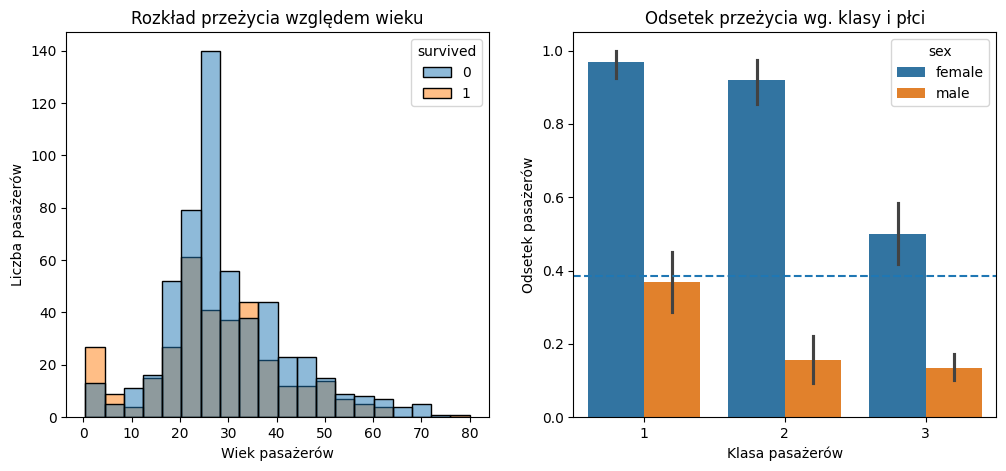

In [12]:
# Twoje rozwiązanie
# new_df = df_clean.fillna(df_clean["age"].mean())
# new_df["age"] = df["age"].fillna(df_clean["age"].mean())
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df_clean, x="age", hue="survived", bins=20, ax=axes[0])
sns.barplot(data=df_clean, x="pclass", y="survived", hue="sex", ax=axes[1])
# sns.histplot(data=new_df, x="age", hue="survived", bins=20, ax=axes[2])
axes[1].axhline(y=df_clean["survived"].mean(), linestyle="--")

axes[0].set_title("Rozkład przeżycia względem wieku")
axes[0].set_xlabel("Wiek pasażerów")
axes[0].set_ylabel("Liczba pasażerów")

axes[1].set_title("Odsetek przeżycia wg. klasy i płci")
axes[1].set_xlabel("Klasa pasażerów")
axes[1].set_ylabel("Odsetek pasażerów")

fig.savefig("titanic.png", dpi=150)

In [13]:
# TEST
import os
assert len(fig.axes) >= 2, "Rysunek powinien mieć dwa wykresy"
assert os.path.exists("titanic.png") and os.path.getsize("titanic.png") > 5000
assert all(ax.get_title() for ax in fig.axes[:2]), "Brakuje tytułów wykresów"
print("D1 OK")

D1 OK


*Twoja odpowiedź:* na histogramie słupki w okolicach 20–30 lat są wyraźnie wyższe od sąsiednich.
1. Skąd się wzięły?
- Wyraźnie wyższe słupki są spowodowane dużym odsetkiem liczby osób w tym przedziale wiekowym, którzy brali udział w rejsie. Dla zobaczenia korelacji przypomnę tylko tabelkę z wartościami średnimi i odchyleniami standardowymi:
          n       mean        std
drop    714  29.699118  14.526497
mean    891  29.699118  13.002015
median  891  29.361582  13.019697
group   891  29.112424  13.304424

2. Jak wyglądałby histogram, gdyby braki uzupełnić jedną medianą?
- Gdyby braki zastąpić jedną wspólną medianą to powstałby histogram z jednym znacząco wyższym od reszty słupkiem.


---
## Część E. Pierwszy klasyfikator

Porównamy trzy klasyfikatory:

1. **Baseline „nikt nie przeżył”** – zawsze 0. To punkt odniesienia: każdy sensowny model musi być od niego lepszy.
2. **Reguła „kobieta → 1”** – wymyślona przez człowieka.
3. **Klasyfikator z tabeli przestawnej** – reguła **wyznaczona z danych**: dla każdej grupy (płeć, klasa) odczytujemy z `pivot` odsetek ocalałych i przewidujemy 1, jeśli przekracza 0.5. To najprostsza forma uczenia: model „zapamiętuje”, co zwykle działo się w danej grupie.

Do przypisania każdemu pasażerowi wartości jego grupy przyda się `transform` (jak w B2):
```python
rate = df_clean.groupby(["sex", "pclass"])["survived"].transform("mean")   # wartość z pivot dla każdego wiersza
```

### Zadanie E1. Trzy klasyfikatory
1. `y` – kolumna `survived` jako tablica NumPy (`to_numpy()`).
2. `y_zero`, `y_rule`, `y_pivot` – predykcje trzech klasyfikatorów (tablice liczb całkowitych 0/1).
3. `m_zero`, `m_rule`, `m_pivot` – ich metryki (`binary_metrics`).
4. `df_models` – tabela z wierszami `"zawsze-zero"`, `"kobieta → 1"`, `"tabela przestawna"` i kolumnami `TP`, `FP`, `FN`, `TN`, `accuracy`, `precision`, `recall`, `f1`.
5. Sprawdź jeden z wyników funkcją `classification_report` ze `sklearn.metrics`.

In [14]:
from sklearn.metrics import classification_report

rate = df_clean.groupby(["sex", "pclass"])["survived"].transform("mean") # wartość z pivot dla każdego wiersza

# Twoje rozwiązanie
y = df_clean["survived"].to_numpy()
y_zero = np.zeros_like(y)
y_rule = (df_clean["sex"] == "female").astype(int).to_numpy()
y_pivot = (rate > 0.5).astype(int).to_numpy()

m_zero = binary_metrics(y, y_zero)
m_rule = binary_metrics(y, y_rule)
m_pivot = binary_metrics(y, y_pivot)


df_wiersze = ["zawsze-zero", "kobieta → 1", "tabela przestawna"]
df_kolumny = ["TP", "FP", "FN", "TN", "accuracy", "precision", "recall", "f1"]

df_models = [
    [m_zero['TP'], m_zero['FP'], m_zero['FN'], m_zero['TN'], m_zero['accuracy'], m_zero['precision'], m_zero['recall'], m_zero['f1']],
    [m_rule['TP'], m_rule['FP'], m_rule['FN'], m_rule['TN'], m_rule['accuracy'], m_rule['precision'], m_rule['recall'], m_rule['f1']],
    [m_pivot['TP'], m_pivot['FP'], m_pivot['FN'], m_pivot['TN'], m_pivot['accuracy'], m_pivot['precision'], m_pivot['recall'], m_pivot['f1']],
]

df_models = pd.DataFrame(df_models, index=df_wiersze, columns=df_kolumny)
print(df_models, "\n\n")

print(classification_report(y, y_rule))

                    TP  FP   FN   TN  accuracy  precision    recall        f1
zawsze-zero          0   0  342  549  0.616162   0.000000  0.000000  0.000000
kobieta → 1        233  81  109  468  0.786756   0.742038  0.681287  0.710366
tabela przestawna  161   9  181  540  0.786756   0.947059  0.470760  0.628906 


              precision    recall  f1-score   support

           0       0.81      0.85      0.83       549
           1       0.74      0.68      0.71       342

    accuracy                           0.79       891
   macro avg       0.78      0.77      0.77       891
weighted avg       0.78      0.79      0.78       891



In [15]:
# TEST
assert m_zero["recall"] == 0.0 and abs(m_zero["accuracy"] - 0.6162) < 1e-3
assert (m_rule["TP"], m_rule["FP"], m_rule["FN"], m_rule["TN"]) == (233, 81, 109, 468)
assert (m_pivot["TP"], m_pivot["FP"], m_pivot["FN"], m_pivot["TN"]) == (161, 9, 181, 540)
assert list(df_models.index) == ["zawsze-zero", "kobieta → 1", "tabela przestawna"]
assert {"accuracy", "precision", "recall", "f1"} <= set(df_models.columns)
print("E1 OK")

E1 OK


### Zadanie E2. Wnioski
Odpowiedz krótko, odwołując się do liczb z `df_models`:

1. O ile oba klasyfikatory poprawiają accuracy względem baseline'u? Dlaczego samo „accuracy = 0.79” bez baseline'u niewiele mówi?
2. Reguła „kobieta → 1” i klasyfikator z tabeli przestawnej mają **identyczną** accuracy. Czym się różnią? Kim są osoby, które klasyfikator z tabeli przestawnej „zmienił” w porównaniu z regułą?
3. Który z nich wybrał(a)byś, gdyby fałszywy alarm (FP) był bardzo kosztowny? A gdyby kosztowne było przeoczenie (FN)?
4. Klasyfikator z tabeli przestawnej „nauczył się” na tych samych danych, na których go oceniamy. Dlaczego taka ocena jest zbyt optymistyczna? Co by się stało, gdyby grup było bardzo dużo, a w każdej po kilka osób?
5. Te reguły decydują na podstawie płci. Podaj zastosowanie, w którym taka reguła byłaby niedopuszczalna niezależnie od accuracy, i wyjaśnij dlaczego.


1. Oba klasyfikatory poprawiają accuracy o 0.17 względem baseline'u. Bez baseline'u nie mamy punktu odniesienia, który pomaga nam stwierdzić skuteczność modelu.

2. Te klasyfikatory różnią się wartościami reszty metryk ("precision", "recall", "f1"). To kobiety z 3. klasy, gdzie odsetek przeżycia=0.5, więc tam działa reguła „kobieta → 0” zamiast „kobieta → 1”, co skutkuje większą ostrożnością (precision = 0,947, recall = 0,471)

3. Wybrałbym kolejno:
  - gdy fałszywy alarm (FP) był kosztowny: tabela przestawna
  - gdy przeoczenie (FN) było kosztowne: kobieta → 1

4. Taka ocena jest zbyt optymistyczna, gdyż inne zbiory danych wykazałyby niższą skuteczność zbioru. Przy dużej ilości grup po kilka osób skuteczność modelu by się "rozjechała".

5. Taka reguła byłaby niedopuszczalna w modelach oceniających podania o pracę w instytucjach na terenie Unii Europejskiej, ponieważ praktyki segregacji płciowej są zakazane w rekrutacji na terenie UE.

---
## Część F. Zadania dodatkowe (dla chętnych / do domu)

**F1. Kobiety i dzieci.** Zbuduj regułę „kobieta **lub** dziecko poniżej 10 lat → 1”, policz metryki i dopisz wiersz do `df_models`. Co się poprawiło, a co pogorszyło? Ile dzieci z brakującym wiekiem reguła „przeoczyła”, bo dostały medianę grupy (wskazówka: `age_missing`)?

**F2. Więcej grup = lepiej?** Dodaj kolumnę `age_group` (`pd.cut(df_clean["age"], bins=[0, 10, 18, 40, 60, 100])`) i zbuduj klasyfikator z tabeli przestawnej dla grup (płeć, klasa, `age_group`). Policz accuracy. Ile grup ma mniej niż 10 osób? Wróć do pytania E2.4.

**F3. Próg na cenę biletu.** Potraktuj cenę biletu jako „wynik modelu”: `y_hat = (df_clean["fare"] >= t)`. Dla 50 progów `t` od 0 do 100 policz precision, recall i F1, narysuj krzywe w funkcji `t` (seaborn albo matplotlib). Przy jakim progu F1 jest największe?

In [16]:
# Twoje rozwiązanie